In [ ]:
from datetime import datetime

import matplotlib.pyplot as plt
import metpy.calc as mpcalc
from metpy.units import units, pandas_dataframe_to_unit_arrays
from siphon.simplewebservice.wyoming import WyomingUpperAir

## Thermodynamic Calculations

MetPy has in increasing number of available calculations that can be performed on sounding data.

* LCL
* LFC
* EL
* CAPE
* CIN

Documentation of MetPy calculations at https://unidata.github.io/MetPy/latest/api/generated/metpy.calc.html



In [ ]:
date = datetime(2011, 4, 27, 0)
station = 'BMX'

#DRL read in data
df = WyomingUpperAir.request_data(date, station)
data_with_units = pandas_dataframe_to_unit_arrays(df)

# Only want to pull in data up to 100 mb, we can 
# use a boolean array to choose on the desired values
ip100 = data_with_units['pressure'] >= 100 * units.hPa

# Subset pressure and read in other data to only 100 mb
p = data_with_units['pressure'][ip100]

#DRL add


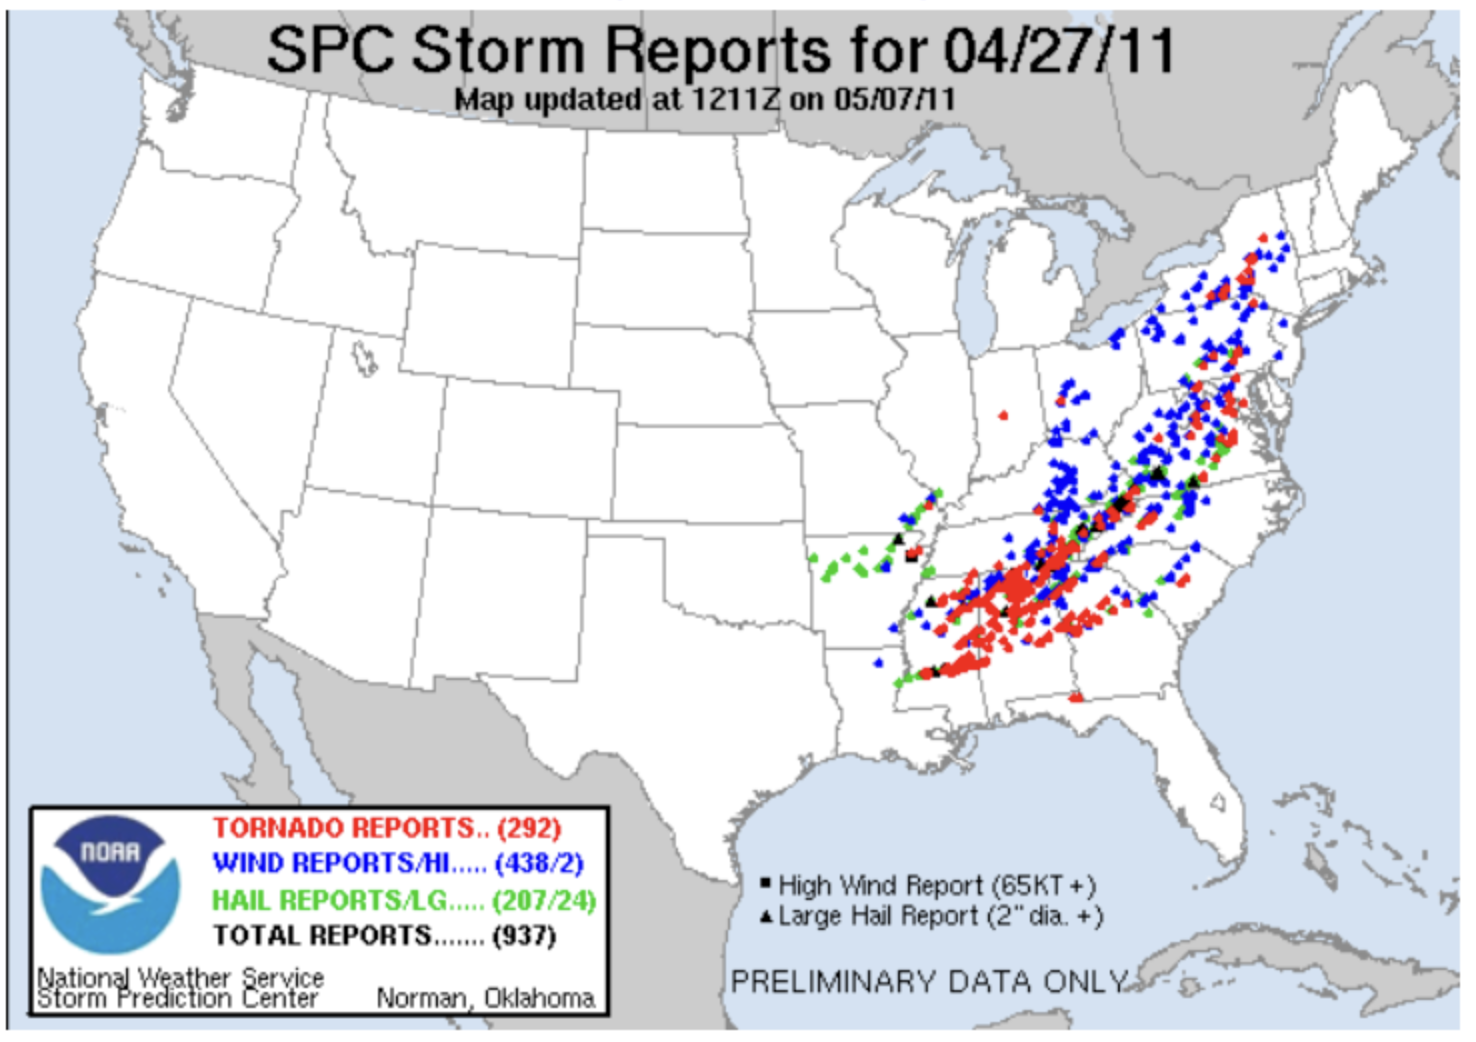

## Compute the Potential Temperature

The difficult part of using functions from modules to compute them is figuring out how they work and what you need to feed the function. Potential temperature is a valuable variable that takes a parcel at a given pressure level and brings it adiabatically to 1000-hPa. Mathematically it is

$$\theta = T \big(\frac{p}{p_0}\big)^\frac{R_d}{C_p}$$

So to calculate the potential temperature you need the temperatre and pressure levels of those temperatures.

https://unidata.github.io/MetPy/latest/api/generated/metpy.calc.potential_temperature.html

In [ ]:
# Use Metpy "mpcalc" (has some geeky met methods)


# Breaks without units 🤔


In [ ]:
#DRL That example was one value... We can do the sounding all at once


## Example Calculation Function from MetPy

Calculating a parcel profile can also be done using MetPy.

```python
def parcel_profile(pressure, temperature, dewpt):
"""Calculate the profile a parcel takes through the atmosphere.

    The parcel starts at `temperature`, and `dewpt`, lifted up
    dry adiabatically to the LCL, and then moist adiabatically from there.
    `pressure` specifies the pressure levels for the profile.

    Parameters
    ----------
    pressure : `pint.Quantity`
        The atmospheric pressure level(s) of interest. This array must be from
        high to low pressure.
    temperature : `pint.Quantity`
        The starting temperature
    dewpt : `pint.Quantity`
        The starting dewpoint

    Returns
    -------
    `pint.Quantity`
        The parcel temperatures at the specified pressure levels.

    See Also
    --------
    lcl, moist_lapse, dry_lapse

    """
    _, _, _, t_l, _, t_u = _parcel_profile_helper(pressure, temperature, dewpt)
    return concatenate((t_l, t_u))
```

So the input is all of the pressures from the sounding you are calculating the profile for, with the temperature and dewpoint of the parcel that will be lifted to generate the parcel profile temperature.

In [ ]:
#Print sfc temperature and dewpoint from sounding


In [ ]:
# Calculate parcel ascent!
                        #[0] is a surface-based parcel  


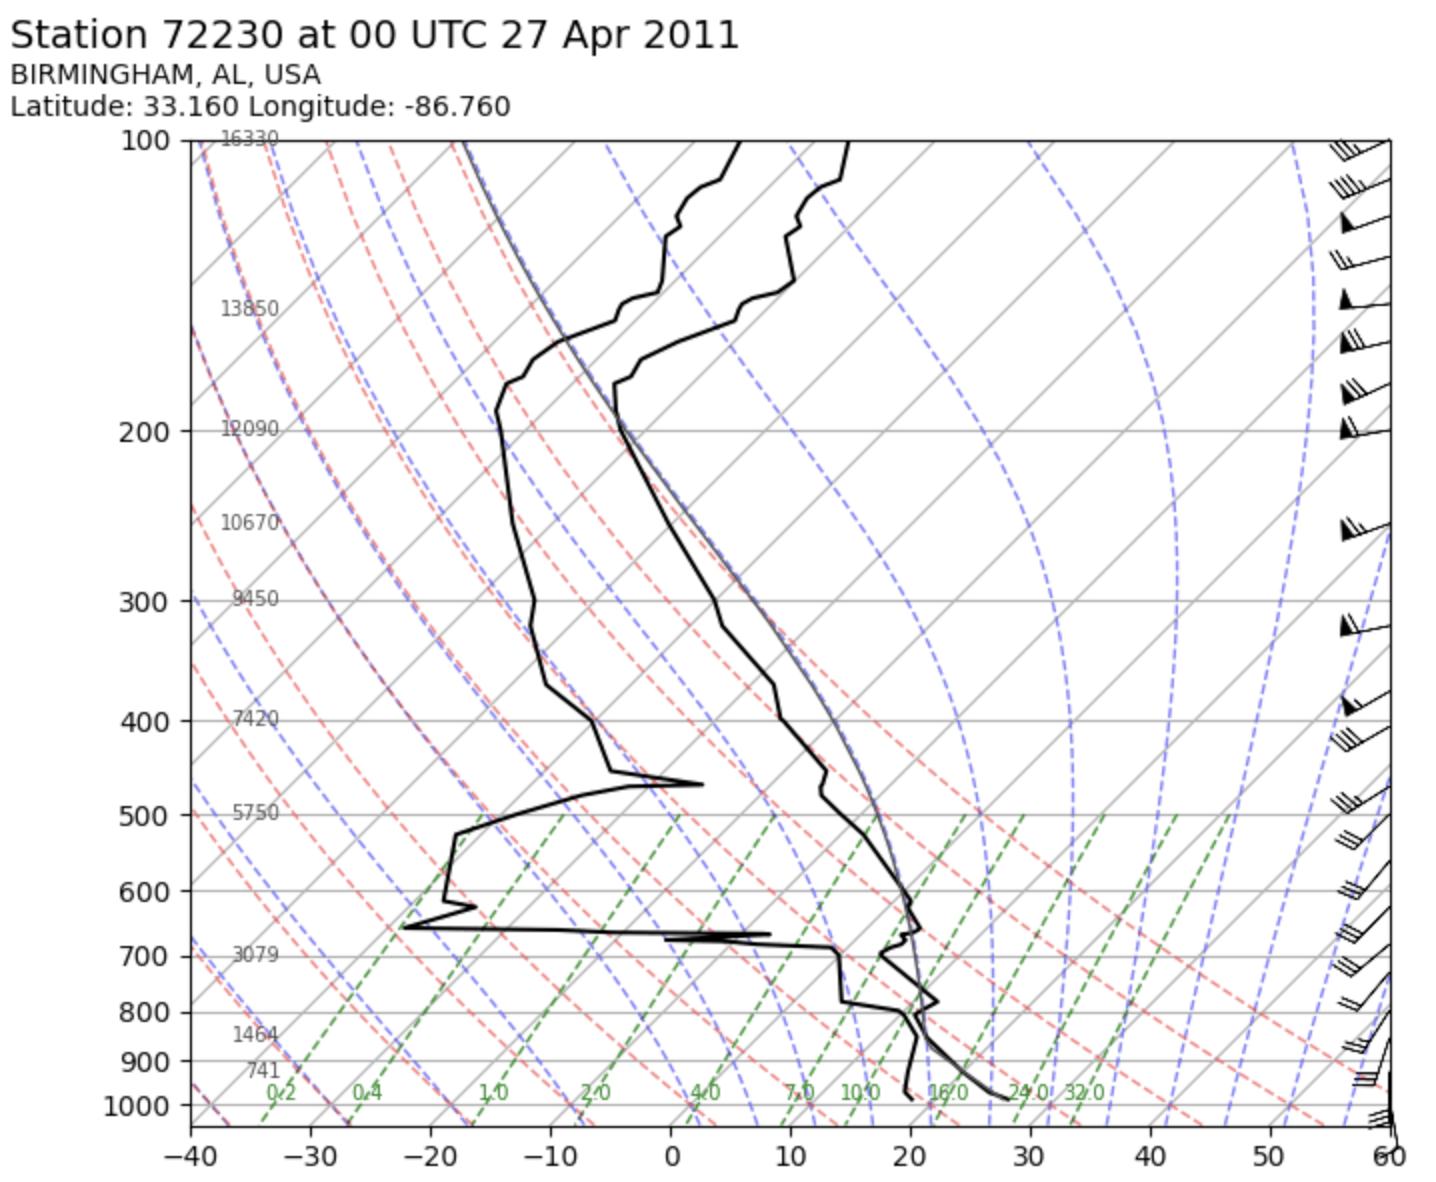

In [ ]:
# Assign parcel ascent to a variable


CAPE, or Convective Available Potential Energy, is the amount of fuel available to a developing thunderstorm. More specifically, it describes atmospheric instability and provides an approximation of updraft strength in a thunderstorm. A higher value of CAPE means the atmosphere is more unstable and would therefore produce a stronger updraft.   

$$ \mathrm{CAPE} = \int_{\mathrm{LFC}}^{\mathrm{EL}} g \left( \frac{T_{v,\mathrm{parcel}} - T_{v,\mathrm{env}}} {T_{v,\mathrm{env}}} \right) \, dz $$

$$ T_v \approx T(1 + 0.61\,r) $$  

where r is the water vapor mixing ratio (kg $kg^{-1}$).

$T_{v}$ is the temperature that a parcel of dry air would need to have in order to have the same density as the moist air parcel.


CAPE is a measure of buoyancy, and so it depends on air density, which is a function of moisture content!

In [ ]:
#Note that the MetPy sounding functions work on 1D arrays only! ☠️



The lifted index is just the straight-up temperature difference at 500 hPa
$$ LI = T_{500,\mathrm{env}} - T_{500,\mathrm{parcel}} $$

- LI > 0: Parcel is colder than the environment → stable atmosphere.
- LI = 0: Neutral stability.
- LI < 0: Parcel is warmer than the environment → unstable atmosphere.
> $>$+3    Stable  
> 0 to +3  Slightly stable  
> 0 to -3  Slightly unstable  
> -3 to -6 Moderately unstable  
< -6       Very unstable

In [ ]:
import numpy as np
#Lifted Index
#Don't forget to strip! 🙈

#Use numpy where command to locate 500 hPa


## Lifting Condensation Level (LCL) Example Calculation

The Lifting Condensation Level (LCL) is the height (or pressure level) at which an unsaturated air parcel becomes saturated when lifted adiabatically.

At that level:

- Relative humidity = 100%
- Condensation begins
- Cloud base forms
- The parcel follows a moist adiabatic lapse rate above this point

## MetPy mpcalc function
With some functions, we get more than one output (similar to the `np.where` function and so on). For certain index calculations, we'll have both a pressure level and a temperature returned by the function.

In [1]:
#Note that this call returns two things! The pressure level and LCL temperature


These two can be immediately unpacked by having two variable names to the left of the equal sign. This makes things a little nice to work with for reporting and plotting purposes.

In [ ]:
#Save the output


In [ ]:
#Print the output


In [ ]:
#Print the surface pressure, temperature, and dew point for skewT assessment!


SkewT

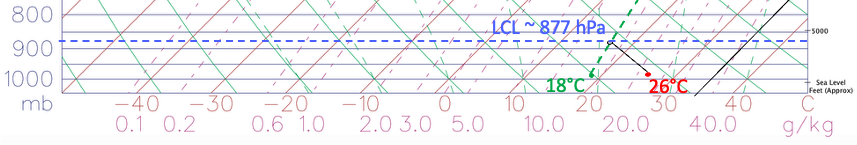